# EDA: avaliações da Olist

Análise exploratória anterior à modelagem: o que há nos dados e o que pode distorcer as etapas
seguintes (duplicatas, nota que não corresponde ao texto, lojas anonimizadas).

Pré-requisito: `python scripts/download_data.py` e `python -m src.data_prep`.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

from src.config import DATA_PROCESSED, FIGURES

FIGURES.mkdir(parents=True, exist_ok=True)
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#c9c8c3", "font.size": 10,
})

r = pd.read_parquet(DATA_PROCESSED / "reviews.parquet")
corpus = pd.read_parquet(DATA_PROCESSED / "corpus.parquet")
print(f"{len(r):,} avaliações | {r.order_id.nunique():,} pedidos | {len(corpus):,} com texto (únicas)")

99,224 avaliações | 98,673 pedidos | 42,370 com texto (únicas)


## Qualidade dos dados

- 814 `review_id` aparecem em mais de um pedido (a mesma avaliação copiada para pedidos feitos juntos) e 551 pedidos
  têm mais de uma avaliação. Para texto, a deduplicação é por `review_id`; para os indicadores, uma linha por par.
- Só ~43% das avaliações têm comentário, e as que têm são mais negativas (abaixo).

In [2]:
print("review_id repetidos:", r.review_id.duplicated().sum())
print("pedidos com mais de uma avaliação:", r.order_id.duplicated().sum())
print()
print(r.groupby("has_text").is_negative.mean().rename({False: "sem texto", True: "com texto"}).map("{:.1%}".format))

review_id repetidos: 814
pedidos com mais de uma avaliação: 551

has_text
sem texto     6.3%
com texto    25.8%
Name: is_negative, dtype: str


## Distribuição das notas

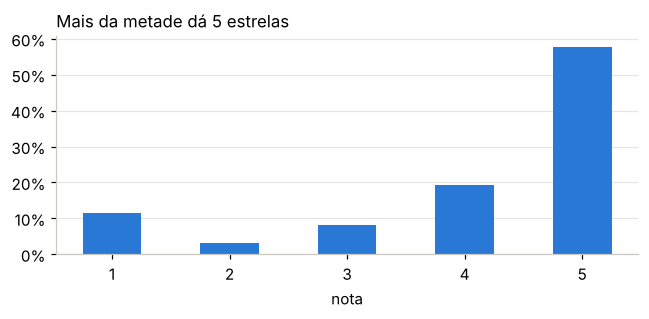

review_score
1    11.5%
2     3.2%
3     8.2%
4    19.3%
5    57.8%
Name: proportion, dtype: str

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
dist = r.review_score.value_counts(normalize=True).sort_index()
ax.bar(dist.index.astype(str), dist.values, color=AZUL, width=0.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("nota"); ax.grid(axis="x", visible=False)
ax.set_title("Mais da metade dá 5 estrelas", loc="left", fontsize=11)
plt.tight_layout(); plt.show()
dist.map("{:.1%}".format)

Distribuição em "J": muitas notas 5, um bloco de notas 1 e pouco no meio, padrão comum em marketplaces.
Para o classificador, isso significa classes desbalanceadas (daí `class_weight="balanced"`).

## Atraso na entrega

A Olist informa ao cliente uma data estimada de entrega. A comparação com a data real é feita por dia,
porque a data estimada vem sempre à meia-noite.

In [4]:
print(f"entregues com atraso: {r.is_late.astype(float).mean():.1%}")
print(f"chegaram 7+ dias ANTES do previsto: {(r.delay_days < -7).mean():.1%}")
print(f"mediana de (entrega - estimativa): {r.delay_days.median():.0f} dias")

entregues com atraso: 6.7%
chegaram 7+ dias ANTES do previsto: 71.9%
mediana de (entrega - estimativa): -12 dias


A estimativa é conservadora: o pedido típico chega 12 dias antes do prometido. Os dados não dizem se isso
é uma política deliberada.

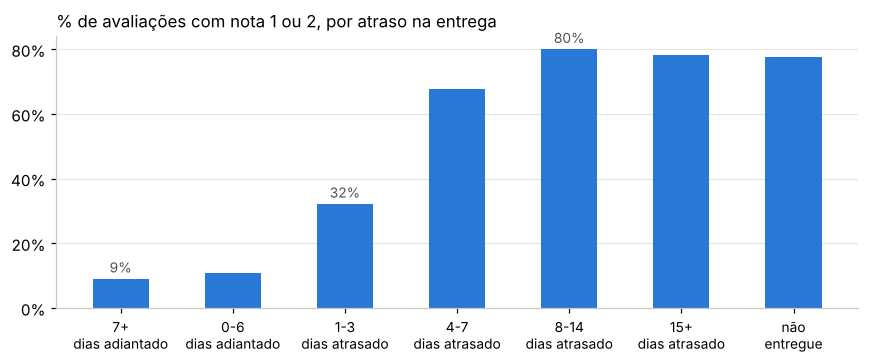

,mean,size
delay_bucket,,
7+ dias adiantado,9.0%,76180
0-6 dias adiantado,10.8%,13769
1-3 dias atrasado,32.2%,1856
4-7 dias atrasado,67.7%,1756
8-14 dias atrasado,80.0%,1453
15+ dias atrasado,78.3%,1345
não entregue,77.7%,2865


In [5]:
ordem = ["7+ dias adiantado", "0-6 dias adiantado", "1-3 dias atrasado", "4-7 dias atrasado",
         "8-14 dias atrasado", "15+ dias atrasado", "não entregue"]
neg = r.groupby("delay_bucket").is_negative.agg(["mean", "size"]).reindex(ordem)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(range(len(neg)), neg["mean"], color=AZUL, width=0.5)
ax.set_xticks(range(len(neg)), [o.replace(" ", "\n", 1) for o in ordem], fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.grid(axis="x", visible=False)
for i, v in enumerate(neg["mean"]):
    if i in (0, 2, 4):
        ax.text(i, v + 0.02, f"{v:.0%}", ha="center", fontsize=9, color="#52514e")
ax.set_title("% de avaliações com nota 1 ou 2, por atraso na entrega", loc="left", fontsize=11)
plt.tight_layout()
fig.savefig(FIGURES / "atraso_vs_negativas.png", dpi=150, bbox_inches="tight")
plt.show()
neg.assign(mean=neg["mean"].map("{:.1%}".format))

Relação forte: no prazo, ~9-11% de avaliações negativas; com 1 a 3 dias de atraso, 32%; acima de uma semana,
cerca de 80%, praticamente o mesmo que não receber. Correlação entre `is_late` e `is_negative`: ~0,40, alta para
duas variáveis binárias.

## Pedidos com mais de um vendedor

Na Olist, um pedido com produtos de lojas diferentes chega em pacotes separados, o que pode gerar reclamações
do tipo "só veio metade".

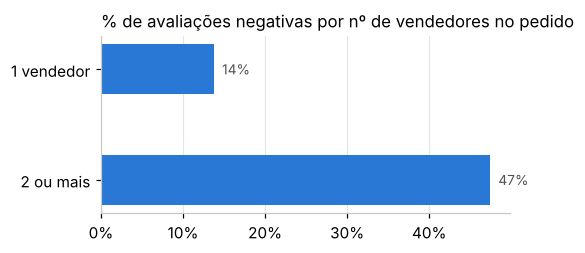

,mean,size
vendedores,,
1 vendedor,0.137539,97187
2 ou mais,0.474178,1278


In [6]:
g = r.assign(vendedores=r.n_sellers.clip(upper=2).map({1: "1 vendedor", 2: "2 ou mais"}))
tab = g.groupby("vendedores").is_negative.agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(5, 2.4))
ax.barh(tab.index[::-1], tab["mean"][::-1], color=AZUL, height=0.45)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
for i, v in enumerate(tab["mean"][::-1]):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9, color="#52514e")
ax.set_title("% de avaliações negativas por nº de vendedores no pedido", loc="left", fontsize=11)
plt.tight_layout(); fig.savefig(FIGURES / "vendedores_vs_negativas.png", dpi=150, bbox_inches="tight"); plt.show()
tab

47% contra 14%. São só ~1.300 pedidos, mas o efeito é grande e aparece nos textos ("comprei 2 e só chegou 1").
Relaciona-se com a categoria `missing_items` usada mais adiante.

## Volume no tempo

order_purchase_timestamp
2017-11-24    1176
2017-11-25     499
2017-11-27     403
Name: count, dtype: int64


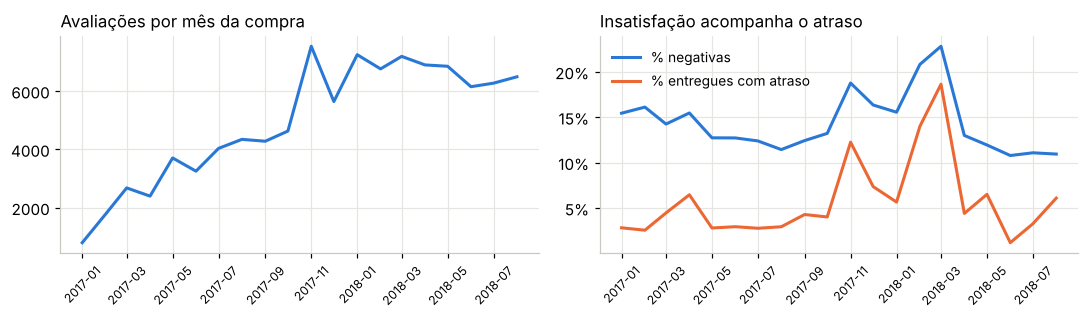

In [7]:
o = pd.read_csv("../data/raw/olist_orders_dataset.csv", parse_dates=["order_purchase_timestamp"])
print(o.order_purchase_timestamp.dt.date.value_counts().head(3))
m = r[(r.purchase_month >= "2017-01-01") & (r.purchase_month <= "2018-08-01")].groupby("purchase_month").agg(
    avaliacoes=("review_id", "size"), negativas=("is_negative", "mean"), atraso=("is_late", lambda x: x.astype(float).mean()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=True)
axes[0].plot(m.index, m.avaliacoes, color=AZUL, lw=2)
axes[0].set_title("Avaliações por mês da compra", loc="left", fontsize=11)
axes[1].plot(m.index, m.negativas, color=AZUL, lw=2, label="% negativas")
axes[1].plot(m.index, m.atraso, color=LARANJA, lw=2, label="% entregues com atraso")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
axes[1].legend(frameon=False, fontsize=9)
axes[1].set_title("Insatisfação acompanha o atraso", loc="left", fontsize=11)
for ax in axes:
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
plt.tight_layout(); fig.savefig(FIGURES / "evolucao_mensal.png", dpi=150, bbox_inches="tight"); plt.show()

- 24/11/2017 (Black Friday) teve 1.176 pedidos, o maior pico diário da base.
- As compras de nov/2017 e de fev-mar/2018 concentram os maiores picos de atraso e de avaliação negativa;
  as duas curvas andam juntas, o que aponta para logística.
- O período exibido vai de jan/2017 a ago/2018; fora dele, o volume mensal é muito baixo.

## Por categoria e por estado

In [8]:
cat = r.groupby("macro_category").is_negative.agg(["mean", "size"]).query("size > 900").sort_values("mean")
print(cat.assign(mean=cat["mean"].map("{:.1%}".format)).to_string())
uf = r.groupby("customer_state").agg(negativas=("is_negative", "mean"), atraso=("is_late", lambda x: x.astype(float).mean()),
                                     n=("review_id", "size")).query("n > 300").sort_values("negativas")
print()
print(uf.head(3).round(3).to_string()); print("..."); print(uf.tail(4).round(3).to_string())

                            mean   size
macro_category                         
Alimentos e bebidas        10.2%    958
Livros, papelaria e mídia  11.0%   3422
Pet shop                   11.5%   1697
Outros                     12.2%   4268
Beleza e saúde             12.8%  11965
Esporte e lazer            12.9%   8340
Eletrodomésticos           13.3%   1995
Ferramentas e construção   13.3%   5481
Bebês e brinquedos         13.8%   6666
Moda e acessórios          13.8%   8997
Automotivo                 14.3%   3877
Eletrônicos e informática  15.5%  15287
Casa e decoração           15.9%  24099
Sem categoria              19.1%   1413

                negativas  atraso      n
customer_state                          
PR                  0.125    0.04   5038
SP                  0.126   0.044  41690
MG                  0.133   0.045  11625
...
                negativas  atraso      n
customer_state                          
RJ                  0.207   0.119  12765
MA                  0.217  

Entre categorias de produto a diferença é pequena (10% a 16%). Entre estados é bem maior: SP e PR ficam em
~12-13%, Alagoas e Maranhão passam de 21% e são também os estados com mais atraso. A localização do cliente pesa
mais do que a categoria do produto.

## Texto: o que tem lá dentro

In [9]:
print(corpus.review_text.str.len().describe().round(0))
got = corpus.review_text.str.lower().str.contains("lannister|stark|targaryen|baratheon").sum()
print(f"\navaliações citando loja anonimizada com nome de Game of Thrones: {got}")
corpus[corpus.review_text.str.lower().str.contains("lannister")].review_text.head(4).tolist()

count    42370.0
mean        69.0
std         55.0
min          1.0
25%         27.0
50%         53.0
75%         95.0
max        229.0
Name: review_text, dtype: float64

avaliações citando loja anonimizada com nome de Game of Thrones: 1955


['Comprei uma capa para um tablet e a que foi entregue não foi a que escolhi no site da lannister. Não emitiram a nota fiscal do produto. Nunca mais compro nada desses parceiros da lannister.',
 'Comprei dois produtos desta loja parceira da lannister e nenhum foi entregue, ja faz Mais de dois meses e NEM Dao retorno ...',
 'o produto demorou MUITO PARA CHEGAro q NÃO É COMUM TRATANDO-SE DE lannister.COM já conheciaa escovae não entendo pq tem preços disparatados como os que paguei. R$ 128, R$50,00, R$55, etc+ frete.',
 'Já comprei várias vezes no site "lannister";mas desta última vez,fiz uma compra de um TONER no 04.10.16 e só prometeram p/ 25.11.16 e ainda não recebi o produto.']

Textos curtos (mediana ~50 caracteres), com muitos erros de digitação e caixa alta. A Olist substituiu o nome
das lojas por casas de Game of Thrones ("lojas lannister"). A normalização troca esses nomes por "loja", para que o
modelo não trate "lannister" como sinal de sentimento.

In [10]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

def termos(textos, n=12):
    v = CountVectorizer(ngram_range=(2, 2), min_df=20)
    X = v.fit_transform(textos)
    s = np.asarray(X.sum(0)).ravel()
    return pd.Series(s, index=v.get_feature_names_out()).sort_values(ascending=False).head(n)

neg_txt = corpus[corpus.review_score <= 2].text_norm
pos_txt = corpus[corpus.review_score >= 4].text_norm
pd.concat({"negativas": termos(neg_txt).reset_index(), "positivas": termos(pos_txt).reset_index()}, axis=1)

negativas              positivas      
             index     0            index     0
0       nao recebi  1960         do prazo  5056
1   recebi produto  1026         antes do  4732
2      produto nao   957        muito bom  2899
3     foi entregue   875         no prazo  1520
4        ainda nao   858     chegou antes  1298
5          nao foi   711   produto chegou  1273
6       do produto   643  super recomendo  1255
7      meu produto   621        dentro do  1054
8       nao chegou   594       produto de  1030
9        ate agora   519    otimo produto   958
10   nao recomendo   451        bem antes   937
11      um produto   398   entrega rapida   851

Nas negativas, os bigramas dominantes são "nao recebi" e "ainda nao", ou seja, entrega. Nas positivas,
"antes do prazo". Também no texto o tema principal é o prazo.

## A nota corresponde ao texto?

A forma mais simples de rotular sentimento é pela nota (1-2 negativo, 3 neutro, 4-5 positivo). A tabela abaixo
compara esse rótulo com o sentimento anotado a partir do texto no conjunto de referência.

In [11]:
from src.gold import load_gold
gold = load_gold()
pd.crosstab(gold.review_score, gold.sentiment, normalize="index").round(2)

sentiment,negative,neutral,positive
review_score,,,
1,0.99,0.00,0.01
2,0.92,0.06,0.02
3,0.56,0.20,0.24
4,0.03,0.17,0.80
5,0.00,0.03,0.97


As notas 1, 2, 4 e 5 correspondem bem ao texto. A nota 3 não: mais da metade é reclamação quando se lê o texto.
Treinar com "3 = neutro" ensina o modelo errado justamente na classe do meio, o que explica o baixo desempenho da
classe neutra em todas as métricas. O treino continua usando o rótulo da nota (é o que existe em escala), mas a
avaliação é sempre feita contra o texto.